# 20 — Uji Jumlah Fold: Skenario 1 vs Baseline Logistic Regression (5, 10, dan 20-fold)

**Dataset:** ABIDE I + ABIDE II (turunan DCAN), 1.638 subjek, 34 situs
**Model:** S1 (GATv2 + cabang linear, fusi atensi) **persis sama** dengan notebook 16, dan baseline Logistic Regression **persis sama** dengan notebook 14

### Latar belakang

Saran dosen pembimbing (bimbingan 15 Okt 2026): seluruh skenario sejauh ini memakai validasi silang **5-fold**, artinya setiap model dilatih pada 80% data dan diuji pada 20%. Jumlah fold menentukan **seberapa banyak data latih** yang dipakai:

| Skema | Latih : uji | Subjek latih per fold (±) |
| :---: | :---: | :---: |
| 5-fold (sekarang) | 80 : 20 | 1.310 |
| **10-fold** | 90 : 10 | 1.474 (+12%) |
| **20-fold** | 95 : 5 | 1.556 (+19%) |

Kurva belajar sebelumnya menunjukkan akurasi masih naik bila data latih bertambah. **Pertanyaan notebook ini:** dengan data latih yang lebih banyak (10-fold atau 20-fold), apakah S1 bisa **melampaui baseline LR**? S1 dipakai sebagai uji coba sebelum skema fold yang sama diterapkan ke seluruh skenario.

### Syarat supaya perbandingan adil

1. **S1 dan LR memakai fold yang sama persis** pada setiap skema. Kalau hanya S1 yang mendapat data latih lebih banyak, kenaikannya bukan bukti S1 lebih baik.
2. Fitur FC tangent **dihitung ulang di setiap fold** dengan titik acuan (rata-rata geometrik) dari **data latih fold itu saja**, sama seperti notebook 10.
3. Model, hyperparameter, seed (5 run), dan cara melatih **tidak diubah** dari notebook 16 dan 14. Yang berubah hanya pembagian fold.
4. Sebagai **kontrol**, LR juga dijalankan pada 5-fold dengan pembagian baru (cara pembagian sama dengan 10/20-fold). Dengan begitu bisa dilihat apakah perubahan berasal dari **jumlah fold** atau hanya dari **pembagian ulang** subjek.

### Aturan keputusan (ditetapkan sebelum hasil keluar)

| Hasil | Keputusan |
| :--- | :--- |
| Akurasi **S1 ensemble > LR** pada skema k (fold sama) | skema k dipakai untuk seluruh skenario S1–S4 (dijalankan ulang, LR juga) |
| S1 menang di 10-fold **dan** 20-fold | pilih **10-fold** (lebih umum dipakai dan lebih hemat waktu) |
| S1 ensemble **≤ LR** di semua skema | protokol tetap 5-fold, hasil S1–S4 yang sekarang dipakai |

| | |
| :--- | :--- |
| **Masukan** | `data/processed/kohort_dcan.csv` (notebook 09) · kovarians dan FC korelasi `data/processed/fitur_dcan_22/` (notebook 10) · prediksi S1 5-fold `result/tabel/25_S1_prediksi.csv` (notebook 16) |
| **Keluaran** | `result/tabel/30_*.csv` · `result/metrics/30_uji_kfold.json` · `result/figure/30_*.png` · cache `result/tabel/30_cache_lr/`, `30_cache_s1_k10/`, `30_cache_s1_k20/` |

### Lama proses (perkiraan)

Setiap fold: fitur tangent 3 atlas ±5 menit + LR 3 atlas ±5–10 menit + S1 5 seed ±25 menit.

| Bagian | Perkiraan |
| :--- | :--- |
| 10-fold (LR + S1) | ±6 jam |
| 20-fold (LR + S1) | ±12–13 jam |
| Kontrol LR 5-fold pembagian baru | ±1 jam |

Pelatihan bisa dihentikan dan dilanjutkan: hasil setiap fold disimpan ke cache. Untuk melihat hasil LR lebih dulu, set `JALANKAN_S1 = False` di sel Persiapan (hanya fitur tangent + LR yang dihitung), lalu ubah ke `True` dan jalankan ulang.

## 1. Persiapan

In [1]:
import gc
import sys
import json
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from IPython.display import display
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
while not (ROOT / "data").exists():
    ROOT = ROOT.parent
sys.path.append(str(ROOT))
import importlib
import src.usulan
importlib.reload(src.usulan)
from src.metrics import hitung_metrik
from src.tangent_cepat import rata_rata_geometrik, tangent as tangent_dari_kovarians
from src.usulan import (DEVICE, ModelUsulan, buat_graf, fitur_linear_pca, fitur_simpul_baris, jalankan_cv_usulan, sisi_topk)

# ----- Skema yang diuji -----
SKEMA = {"k10": 10, "k20": 20}      # skema utama: LR + S1
KONTROL_K5 = True                   # LR saja pada 5-fold dengan pembagian baru (kontrol)
JALANKAN_S1 = True                  # False = hanya fitur tangent + LR (cepat), True = LR + S1
SEED_FOLD = 42                      # sama dengan pembagian fold di notebook 09

# ----- Pengaturan S1: SAMA PERSIS dengan notebook 16 (diperiksa di bawah) -----
ATLAS = {"gordon2014": 352, "hcp2016": 379, "markov2012": 205}
ATLAS_GRAF = "hcp2016"
N_SIMPUL = 360
K_SISI = 20
HIPER_MODEL = dict(hidden=64, n_layer=2, heads=4, dropout=0.5, dropout_input=0.2, dropedge=0.2, dropout_linear=0.2, bobot_bantu=0.5)
CFG_LATIH = dict(lr=1e-3, weight_decay=1e-3, batch_size=32, max_epochs=200, min_epochs=20, patience=40, val_size=0.15, seeds=(0, 1, 2, 3, 4))

# ----- Pengaturan LR: SAMA PERSIS dengan notebook 14 -----
GRID_C = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0]
INNER = StratifiedKFold(3, shuffle=True, random_state=42)

PROC = ROOT / "data" / "processed"
FITUR_22 = PROC / "fitur_dcan_22"
TABEL_DIR = ROOT / "result" / "tabel"
FIG_DIR = ROOT / "result" / "figure"
METRIK_DIR = ROOT / "result" / "metrics"
CACHE_LR = TABEL_DIR / "30_cache_lr"
for d in (TABEL_DIR, FIG_DIR, METRIK_DIR, CACHE_LR):
    d.mkdir(parents=True, exist_ok=True)

kohort = pd.read_csv(PROC / "kohort_dcan.csv")
y = kohort["label"].to_numpy()
situs = kohort["situs"].to_numpy()
dataset = kohort["dataset"].to_numpy()
fold5_lama = kohort["fold_gabungan"].to_numpy()
COV = {a: np.load(FITUR_22 / f"cov_{a}.npy", mmap_mode="r") for a in ATLAS}

# pemeriksaan: pengaturan S1 di sini sama dengan yang tercatat dari notebook 16
s1 = json.load(open(METRIK_DIR / "S1_ringkasan.json", encoding="utf-8"))
assert s1["hiper_model"] == HIPER_MODEL, "hyperparameter S1 berbeda dengan notebook 16"
assert {k: (list(v) if isinstance(v, tuple) else v) for k, v in CFG_LATIH.items()} == s1["cfg_latih"], "pengaturan latih berbeda dengan notebook 16"
assert s1["k_sisi"] == K_SISI
print(f"Perangkat: {DEVICE} | subjek {len(y)} (ASD {y.sum()}, kontrol {(1 - y).sum()}) | situs {len(np.unique(situs))}")
print("✓ Hyperparameter dan pengaturan latih S1 identik dengan notebook 16")

Perangkat: cuda | subjek 1638 (ASD 714, kontrol 924) | situs 34
✓ Hyperparameter dan pengaturan latih S1 identik dengan notebook 16


## 2. Membuat Fold Baru

Fold dibuat dengan **StratifiedKFold** pada seluruh 1.638 subjek, bertingkat **situs × diagnosis** (seed 42), supaya setiap fold berisi campuran situs dan proporsi ASD yang seimbang. Pembagian ini dipakai bersama oleh S1 dan LR.

Catatan: fold 5-fold lama (`fold_gabungan`, notebook 09) dibuat sedikit berbeda (ABIDE I memakai fold lamanya, ABIDE II dibagi baru). Karena itu ditambahkan **5-fold pembagian baru** sebagai kontrol untuk LR.

Strata situs × diagnosis yang subjeknya lebih sedikit dari jumlah fold tetap disebar sebisa mungkin; peringatan dari scikit-learn untuk strata kecil itu wajar.

In [2]:
strata = np.array([f"{s}_{l}" for s, l in zip(situs, y)])

def buat_fold(k):
    f = np.zeros(len(y), dtype=int)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for i, (_, te) in enumerate(StratifiedKFold(k, shuffle=True, random_state=SEED_FOLD).split(np.zeros(len(y)), strata)):
            f[te] = i
    return f

FOLD = {nama: buat_fold(k) for nama, k in SKEMA.items()}
if KONTROL_K5:
    FOLD["k5_baru"] = buat_fold(5)

baris = [{"Skema": "k5 (lama, notebook 09)", "Jumlah fold": 5, "Subjek uji per fold": f"{np.bincount(fold5_lama).min()}–{np.bincount(fold5_lama).max()}",
          "Subjek latih per fold (rata-rata)": len(y) - np.bincount(fold5_lama).mean(),
          "ASD per fold uji (%)": f"{pd.Series(y).groupby(fold5_lama).mean().min() * 100:.1f}–{pd.Series(y).groupby(fold5_lama).mean().max() * 100:.1f}"}]
for nama, f in FOLD.items():
    n = np.bincount(f)
    asd = pd.Series(y).groupby(f).mean() * 100
    baris.append({"Skema": nama, "Jumlah fold": len(n), "Subjek uji per fold": f"{n.min()}–{n.max()}",
                  "Subjek latih per fold (rata-rata)": len(y) - n.mean(), "ASD per fold uji (%)": f"{asd.min():.1f}–{asd.max():.1f}"})
display(pd.DataFrame(baris).round(1).style.set_caption("Pembagian fold setiap skema"))

pd.DataFrame({"FILE_ID": kohort["FILE_ID"], "fold_k5_lama": fold5_lama, **{f"fold_{n}": f for n, f in FOLD.items()}}).to_csv(
    TABEL_DIR / "30_fold_kfold.csv", index=False)

,Skema,Jumlah fold,Subjek uji per fold,Subjek latih per fold (rata-rata),ASD per fold uji (%)
0,"k5 (lama, notebook 09)",5,323–335,1310.400000,42.2–44.6
1,k10,10,163–164,1474.200000,40.2–46.3
2,k20,20,81–82,1556.100000,35.4–50.0
3,k5_baru,5,327–328,1310.400000,42.8–45.7


## 3. Fitur FC Tangent per Fold

Untuk setiap fold, titik acuan tangent (rata-rata geometrik kovarians) dihitung **hanya dari data latih fold itu**, lalu seluruh subjek diproyeksikan ke ruang tangent. Ini sama dengan notebook 10, yang menyimpan hasilnya untuk 5 fold lama.

Untuk 10 + 20 fold, menyimpan fitur ke disk butuh ±1 GB per fold (±30 GB total), jadi di sini fitur **dihitung di memori** setiap kali sebuah fold diproses, lalu dibuang.

**Pemeriksaan:** fungsi yang sama dijalankan pada fold 0 skema lama (atlas Markov, yang paling kecil), lalu dicocokkan dengan berkas yang disimpan notebook 10. Hasilnya harus identik.

In [3]:
def tangent_fold(f, k, atlas=None):
    """Fitur tangent semua subjek untuk fold k pada pembagian f; acuan hanya dari data latih (f != k)."""
    latih = np.where(f != k)[0]
    hasil = {}
    for a in (atlas or ATLAS):
        acuan = rata_rata_geometrik(COV[a][latih], max_iter=10, tol=1e-7)
        hasil[a] = tangent_dari_kovarians(COV[a], acuan)
    return hasil

t0 = time.perf_counter()
cek = tangent_fold(fold5_lama, 0, atlas=["markov2012"])["markov2012"]
simpan = np.load(FITUR_22 / "tangent_markov2012_gab_0.npy", mmap_mode="r")
selisih = float(np.abs(cek - np.asarray(simpan)).max())
print(f"Tangent Markov fold 0 (dihitung ulang) vs berkas notebook 10: selisih maksimum {selisih:.2e} ({time.perf_counter() - t0:.0f} detik)")
assert selisih < 1e-5, "fitur tangent tidak sama dengan notebook 10"
print("✓ Fungsi fitur tangent identik dengan notebook 10")
del cek, simpan

Tangent Markov fold 0 (dihitung ulang) vs berkas notebook 10: selisih maksimum 0.00e+00 (61 detik)
✓ Fungsi fitur tangent identik dengan notebook 10


## 4. Baseline Logistic Regression per Fold

Sama dengan notebook 14: untuk setiap atlas, *StandardScaler* + Logistic Regression dengan C dipilih dari 7 nilai lewat validasi silang 3-fold **di dalam data latih** (skor AUC). Probabilitas ketiga atlas lalu dirata-rata.

**Pemeriksaan:** LR atlas Markov fold 0 skema lama dijalankan ulang dan dicocokkan dengan hasil yang disimpan notebook 10/14.

In [4]:
def lr_prob(X, tr, te):
    gs = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
                      {"logisticregression__C": GRID_C}, cv=INNER, scoring="roc_auc", n_jobs=1)
    gs.fit(np.asarray(X[tr]), y[tr])
    return gs.predict_proba(np.asarray(X[te]))[:, 1]

def lr_fold(nama, f, k, V):
    """Probabilitas LR (rata-rata 3 atlas) untuk subjek uji fold k; per atlas disimpan ke cache."""
    tr, te = np.where(f != k)[0], np.where(f == k)[0]
    p = []
    for a in ATLAS:
        berkas = CACHE_LR / f"{nama}_fold{k}_{a}.npz"
        if berkas.exists():
            p.append(np.load(berkas)["p"])
            continue
        pa = lr_prob(V[a], tr, te)
        np.savez(berkas, p=pa, idx=te)
        p.append(pa)
    return np.mean(p, axis=0)

def lr_tersimpan(nama, f):
    """Probabilitas LR seluruh subjek dari cache (NaN bila fold belum dihitung)."""
    p = np.full(len(y), np.nan)
    for k in np.unique(f):
        berkas = [CACHE_LR / f"{nama}_fold{k}_{a}.npz" for a in ATLAS]
        if all(b.exists() for b in berkas):
            p[f == k] = np.mean([np.load(b)["p"] for b in berkas], axis=0)
    return p

# pemeriksaan terhadap notebook 10/14
t0 = time.perf_counter()
tr0, te0 = np.where(fold5_lama != 0)[0], np.where(fold5_lama == 0)[0]
p_cek = lr_prob(np.load(FITUR_22 / "tangent_markov2012_gab_0.npy", mmap_mode="r"), tr0, te0)
p_simpan = np.load(TABEL_DIR / "22_cache" / "C3_gab_tangent_markov2012.npz")["p"][te0]
print(f"LR Markov fold 0 vs notebook 14: selisih probabilitas maksimum {np.abs(p_cek - p_simpan).max():.2e} ({time.perf_counter() - t0:.0f} detik)")
assert np.abs(p_cek - p_simpan).max() < 1e-6
print("✓ Fungsi LR identik dengan notebook 14")

LR Markov fold 0 vs notebook 14: selisih probabilitas maksimum 0.00e+00 (16 detik)
✓ Fungsi LR identik dengan notebook 14


## 5. Pelatihan: LR dan S1 pada Setiap Skema

Untuk setiap fold, fitur tangent dihitung **satu kali**, lalu dipakai bersama oleh LR dan S1:

```
untuk setiap skema (10-fold, 20-fold) dan setiap fold k:
    fitur tangent 3 atlas (acuan dari data latih fold k)
    ├─► LR 3 atlas          → probabilitas subjek uji (cache 30_cache_lr/)
    └─► S1: fitur simpul + PCA cabang linear (statistik dari data latih) → 5 seed → probabilitas (cache 30_cache_s1_<skema>/)
```

Graf (sisi top-20 |korelasi|) tidak bergantung fold, jadi dibuat sekali. Kontrol 5-fold pembagian baru hanya menjalankan LR.

Log setiap seed dicetak saat berjalan; akurasi fold di log hanya sekilas (fold 20-fold berisi ±82 subjek sehingga naik-turunnya besar). Hasil yang dibaca ada di bagian 6.

In [5]:
t0 = time.perf_counter()
SISI = sisi_topk(np.load(FITUR_22 / f"korelasi_{ATLAS_GRAF}.npy", mmap_mode="r"), ATLAS[ATLAS_GRAF], N_SIMPUL, K_SISI)
print(f"Sisi graf siap untuk {len(SISI)} subjek ({time.perf_counter() - t0:.0f} detik)")

def buat_model(contoh):
    return ModelUsulan(N_SIMPUL, d_simpul=contoh.x.size(1), d_linear=contoh.x_lin.size(1), **HIPER_MODEL)

_simpan = {}

def penyiap(nama, f):
    """siapkan_fold untuk jalankan_cv_usulan: hitung tangent, jalankan LR fold itu, lalu bangun data S1."""
    def siapkan_fold(k, idx_latih_penuh):
        if _simpan.get("kunci") == (nama, k):
            return _simpan["data"]
        _simpan.clear()
        gc.collect()
        t1 = time.perf_counter()
        V = tangent_fold(f, k)
        p_lr = lr_fold(nama, f, k, V)
        te = np.where(f == k)[0]
        X_simpul = fitur_simpul_baris(V[ATLAS_GRAF], ATLAS[ATLAS_GRAF], N_SIMPUL, idx_latih_penuh)
        X_linear = fitur_linear_pca([V[a] for a in ATLAS], idx_latih_penuh)
        del V
        gc.collect()
        data = buat_graf(y, X_simpul, SISI, X_linear=X_linear)
        _simpan.update(kunci=(nama, k), data=data)
        print(f"  [{nama} fold {k}] fitur + LR {(time.perf_counter() - t1) / 60:.1f} menit | LR ACC fold {(((p_lr >= 0.5).astype(int)) == y[te]).mean() * 100:.2f}", flush=True)
        return data
    return siapkan_fold

def jalankan_lr_saja(nama, f):
    for k in np.unique(f):
        if all((CACHE_LR / f"{nama}_fold{k}_{a}.npz").exists() for a in ATLAS):
            continue
        t1 = time.perf_counter()
        V = tangent_fold(f, k)
        p_lr = lr_fold(nama, f, k, V)
        del V
        gc.collect()
        print(f"  [{nama} fold {k}] LR {(time.perf_counter() - t1) / 60:.1f} menit | ACC fold {(((p_lr >= 0.5).astype(int)) == y[f == k]).mean() * 100:.2f}", flush=True)

HASIL_S1 = {}
for nama in SKEMA:
    t0 = time.perf_counter()
    print(f"=== {nama} ({SKEMA[nama]}-fold) ===", flush=True)
    if JALANKAN_S1:
        HASIL_S1[nama] = jalankan_cv_usulan(y, situs, FOLD[nama], penyiap(nama, FOLD[nama]), buat_model, cfg=CFG_LATIH,
                                            cache_dir=TABEL_DIR / f"30_cache_s1_{nama}")
        _simpan.clear()
        gc.collect()
    jalankan_lr_saja(nama, FOLD[nama])      # melengkapi LR untuk fold yang S1-nya sudah dari cache, atau bila JALANKAN_S1 = False
    print(f"{nama} selesai dalam {(time.perf_counter() - t0) / 60:.1f} menit", flush=True)

if KONTROL_K5:
    print("=== kontrol: LR 5-fold pembagian baru ===", flush=True)
    jalankan_lr_saja("k5_baru", FOLD["k5_baru"])

P_LR = {nama: lr_tersimpan(nama, f) for nama, f in FOLD.items()}
assert all(np.isfinite(p).all() for p in P_LR.values()), "masih ada fold LR yang belum dihitung"

Sisi graf siap untuk 1638 subjek (10 detik)
=== k10 (10-fold) ===
  [k10 fold 0] fitur + LR 9.5 menit | LR ACC fold 72.56
    fold 0 seed 0: epoch terbaik  23 | AUC val 72.12 | 3.3 menit
    fold 0 seed 1: epoch terbaik  28 | AUC val 78.65 | 3.7 menit
    fold 0 seed 2: epoch terbaik  67 | AUC val 77.43 | 6.2 menit
    fold 0 seed 3: epoch terbaik  44 | AUC val 76.73 | 5.2 menit
    fold 0 seed 4: epoch terbaik  25 | AUC val 77.30 | 4.1 menit
  fold 0: ACC 65.85 | AUC 74.56 (32 menit berjalan)
  [k10 fold 1] fitur + LR 9.6 menit | LR ACC fold 75.00
    fold 1 seed 0: epoch terbaik  94 | AUC val 78.52 | 7.2 menit
    fold 1 seed 1: epoch terbaik  48 | AUC val 72.71 | 5.2 menit
    fold 1 seed 2: epoch terbaik  35 | AUC val 72.97 | 4.6 menit
    fold 1 seed 3: epoch terbaik  20 | AUC val 77.57 | 3.8 menit
    fold 1 seed 4: epoch terbaik  22 | AUC val 75.02 | 3.9 menit
  fold 1: ACC 73.78 | AUC 80.23 (66 menit berjalan)
  [k10 fold 2] fitur + LR 9.4 menit | LR ACC fold 76.22
    fold 2 s

## 6. Hasil

### 6.1 Ringkasan per skema

Cara menghitung metrik **sama dengan notebook 16**: metrik dihitung per fold lalu dirata-rata antar fold.
- **S1 per run**: setiap run (seed) adalah satu validasi silang lengkap; dilaporkan rata-rata ± SD antar 5 run.
- **S1 ensemble**: probabilitas kelima run dirata-rata.
- **LR**: deterministik, satu nilai per skema.

Baris **k5 (lama)** diambil dari hasil notebook 16 (S1) dan 14 (LR) sebagai acuan. Kolom *akurasi gabungan* menghitung akurasi dari seluruh 1.638 subjek sekaligus (tidak dirata-rata per fold), sebagai pembanding yang tidak terpengaruh ukuran fold.

In [6]:
KOLOM = {"accuracy": "Akurasi", "balanced": "Balanced acc.", "sensitivity": "Sensitivitas", "specificity": "Spesifisitas",
         "precision": "Presisi", "f1": "F1", "auc": "AUC"}

def rata_fold(p, f):
    df = pd.DataFrame([hitung_metrik(y[f == k], p[f == k]) for k in np.unique(f)])
    df["balanced"] = (df["sensitivity"] + df["specificity"]) / 2
    return df[list(KOLOM)].mean() * 100

def akurasi_gabungan(p):
    return (((p >= 0.5).astype(int)) == y).mean() * 100

def mcnemar(pa, pb):
    A, B = (pa >= 0.5).astype(int) == y, (pb >= 0.5).astype(int) == y
    n01, n10 = int((~A & B).sum()), int((A & ~B).sum())
    return {"selisih": (B.mean() - A.mean()) * 100, "hanya_benar_model": n01, "hanya_benar_lr": n10,
            "p": stats.binomtest(n01, n01 + n10, 0.5).pvalue if n01 + n10 else 1.0}

# acuan 5-fold lama (notebook 16 + 14)
lama = pd.read_csv(TABEL_DIR / "25_S1_prediksi.csv")
assert (lama["FILE_ID"].to_numpy() == kohort["FILE_ID"].to_numpy()).all() and (lama["fold"].to_numpy() == fold5_lama).all()
SUMBER = {"k5 (lama)": {"f": fold5_lama, "p_run": lama[[f"p_run{r}" for r in range(1, 6)]].to_numpy(),
                        "p_ens": lama["p_ensemble"].to_numpy(), "p_lr": lama["p_lr"].to_numpy()}}
for nama in SKEMA:
    if nama in HASIL_S1:
        SUMBER[nama] = {"f": FOLD[nama], "p_run": HASIL_S1[nama]["p_run"], "p_ens": HASIL_S1[nama]["p"], "p_lr": P_LR[nama]}
if KONTROL_K5:
    SUMBER["k5_baru (kontrol, LR saja)"] = {"f": FOLD["k5_baru"], "p_run": None, "p_ens": None, "p_lr": P_LR["k5_baru"]}

baris, PER_RUN = [], {}
for nama, s in SUMBER.items():
    f = s["f"]
    b = {"Skema": nama, "Fold": len(np.unique(f))}
    m_lr = rata_fold(s["p_lr"], f)
    if s["p_run"] is not None:
        run = pd.DataFrame([rata_fold(s["p_run"][:, r], f) for r in range(s["p_run"].shape[1])])
        PER_RUN[nama] = run
        m_ens = rata_fold(s["p_ens"], f)
        uji = mcnemar(s["p_lr"], s["p_ens"])
        b.update({"S1 per run: akurasi (%)": f"{run['accuracy'].mean():.2f} ± {run['accuracy'].std(ddof=1):.2f}",
                  "S1 per run: AUC (%)": f"{run['auc'].mean():.2f} ± {run['auc'].std(ddof=1):.2f}",
                  "S1 ensemble: akurasi (%)": m_ens["accuracy"], "S1 ensemble: AUC (%)": m_ens["auc"],
                  "LR: akurasi (%)": m_lr["accuracy"], "LR: AUC (%)": m_lr["auc"],
                  "Selisih ensemble − LR (poin)": m_ens["accuracy"] - m_lr["accuracy"],
                  "Run S1 > LR": f"{int((run['accuracy'] > m_lr['accuracy']).sum())} / {len(run)}",
                  "McNemar ensemble vs LR (p)": uji["p"],
                  "Akurasi gabungan S1 ens. / LR (%)": f"{akurasi_gabungan(s['p_ens']):.2f} / {akurasi_gabungan(s['p_lr']):.2f}"})
    else:
        b.update({"LR: akurasi (%)": m_lr["accuracy"], "LR: AUC (%)": m_lr["auc"],
                  "Akurasi gabungan S1 ens. / LR (%)": f"– / {akurasi_gabungan(s['p_lr']):.2f}"})
    baris.append(b)
ringkasan = pd.DataFrame(baris).set_index("Skema")
display(ringkasan.round(2).style.set_caption("S1 vs baseline LR pada 5, 10, dan 20-fold (fold sama untuk kedua model)"))
ringkasan.round(4).to_csv(TABEL_DIR / "30_ringkasan_kfold.csv")

lengkap = []
for nama, s in SUMBER.items():
    f = s["f"]
    if s["p_run"] is not None:
        lengkap.append({"Skema": nama, "Model": "S1 per run (rata-rata)", **{f"{v} (%)": x for v, x in zip(KOLOM.values(), PER_RUN[nama].mean())}})
        lengkap.append({"Skema": nama, "Model": "S1 ensemble", **{f"{v} (%)": x for v, x in zip(KOLOM.values(), rata_fold(s["p_ens"], f))}})
    lengkap.append({"Skema": nama, "Model": "Baseline LR", **{f"{v} (%)": x for v, x in zip(KOLOM.values(), rata_fold(s["p_lr"], f))}})
lengkap = pd.DataFrame(lengkap).set_index(["Skema", "Model"])
display(lengkap.round(2).style.set_caption("Metrik lengkap (rata-rata antar fold)"))
lengkap.round(4).to_csv(TABEL_DIR / "30_metrik_lengkap_kfold.csv")

,Fold,S1 per run: akurasi (%),S1 per run: AUC (%),S1 ensemble: akurasi (%),S1 ensemble: AUC (%),LR: akurasi (%),LR: AUC (%),Selisih ensemble − LR (poin),Run S1 > LR,McNemar ensemble vs LR (p),Akurasi gabungan S1 ens. / LR (%)
Skema,,,,,,,,,,,
k5 (lama),5,70.54 ± 0.27,78.00 ± 0.53,72.450000,79.220000,73.230000,81.350000,-0.780000,0 / 5,0.370000,72.47 / 73.26
k10,5,70.32 ± 1.16,77.59 ± 1.01,72.040000,78.980000,73.810000,81.210000,-1.770000,0 / 5,0.050000,72.04 / 73.81
k20,10,70.93 ± 1.43,77.77 ± 0.75,72.040000,79.470000,74.300000,81.300000,-2.260000,0 / 5,0.010000,72.04 / 74.30
"k5_baru (kontrol, LR saja)",20,nan,nan,nan,nan,72.830000,80.490000,nan,nan,nan,– / 72.83


### 6.2 Grafik perbandingan

- **Kiri:** akurasi S1 per run (batang = rata-rata, titik = setiap run), S1 ensemble, dan LR untuk setiap skema.
- **Kanan:** sama untuk AUC.

Yang dicari: apakah batang S1 (terutama ensemble) **melewati** batang LR pada skema yang sama.

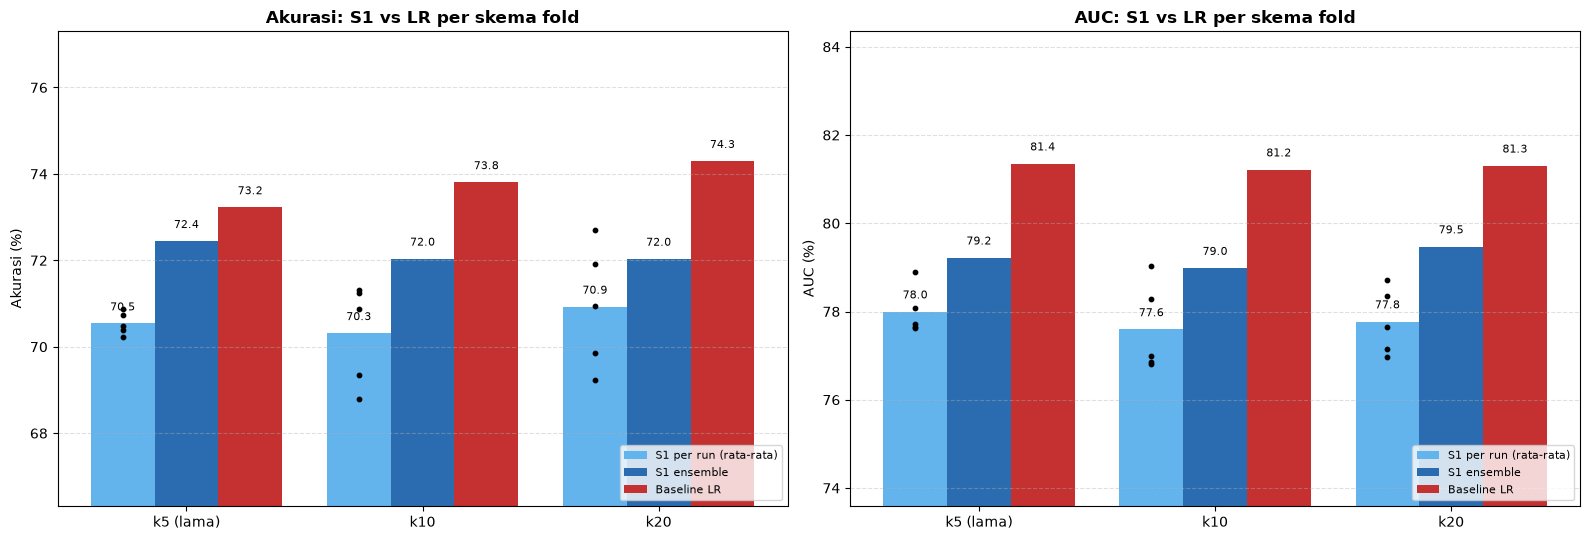

In [7]:
nama_skema = [n for n in SUMBER if SUMBER[n]["p_run"] is not None]
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, m, judul in [(axes[0], "accuracy", "Akurasi"), (axes[1], "auc", "AUC")]:
    x = np.arange(len(nama_skema))
    run_rata = [PER_RUN[n][m].mean() for n in nama_skema]
    ens = [rata_fold(SUMBER[n]["p_ens"], SUMBER[n]["f"])[m] for n in nama_skema]
    lr = [rata_fold(SUMBER[n]["p_lr"], SUMBER[n]["f"])[m] for n in nama_skema]
    ax.bar(x - 0.27, run_rata, 0.27, color="#63B3ED", label="S1 per run (rata-rata)")
    for xi, n in zip(x, nama_skema):
        ax.scatter(np.full(len(PER_RUN[n]), xi - 0.27), PER_RUN[n][m], color="black", s=10, zorder=3)
    ax.bar(x, ens, 0.27, color="#2B6CB0", label="S1 ensemble")
    ax.bar(x + 0.27, lr, 0.27, color="#C53030", label="Baseline LR")
    for xs, vals in [(x - 0.27, run_rata), (x, ens), (x + 0.27, lr)]:
        for xi, v in zip(xs, vals):
            ax.text(xi, v + 0.3, f"{v:.1f}", ha="center", fontsize=8)
    lo = min(min(run_rata), min(ens), min(lr))
    ax.set_ylim(lo - 4, max(max(ens), max(lr), max(run_rata)) + 3)
    ax.set_xticks(x); ax.set_xticklabels(nama_skema)
    ax.set_ylabel(f"{judul} (%)"); ax.set_title(f"{judul}: S1 vs LR per skema fold", fontweight="bold")
    ax.grid(axis="y", alpha=0.4, ls="--"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
fig.savefig(FIG_DIR / "30_1_kfold_s1_vs_lr.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.3 Uji kebermaknaan terhadap LR

Uji McNemar per subjek (pasangan prediksi pada subjek yang sama), untuk setiap run dan ensemble S1 dibanding LR **pada skema yang sama**, dengan koreksi Holm per skema. "Setara" berarti selisihnya tidak bermakna secara statistik.

In [8]:
tabel_uji = []
for nama in nama_skema:
    s = SUMBER[nama]
    calon = {**{f"S1 run {r + 1}": s["p_run"][:, r] for r in range(s["p_run"].shape[1])}, "S1 ensemble": s["p_ens"]}
    u = pd.DataFrame([{"Skema": nama, "Model": n, **mcnemar(s["p_lr"], p)} for n, p in calon.items()])
    urut = np.argsort(u["p"].to_numpy())
    u.loc[u.index[urut], "p Holm"] = np.minimum(1, np.maximum.accumulate(u["p"].to_numpy()[urut] * (len(u) - np.arange(len(u)))))
    u["Kesimpulan"] = np.where(u["p Holm"] >= 0.05, "setara", np.where(u["selisih"] > 0, "S1 lebih baik (bermakna)", "S1 lebih rendah (bermakna)"))
    tabel_uji.append(u)
tabel_uji = pd.concat(tabel_uji, ignore_index=True).rename(columns={
    "selisih": "Selisih akurasi gabungan (poin)", "hanya_benar_model": "Hanya benar di S1", "hanya_benar_lr": "Hanya benar di LR"})
display(tabel_uji.round(4).style.set_caption("Uji McNemar S1 vs LR (koreksi Holm per skema)"))
tabel_uji.to_csv(TABEL_DIR / "30_uji_mcnemar_kfold.csv", index=False)

,Skema,Model,Selisih akurasi gabungan (poin),Hanya benar di S1,Hanya benar di LR,p,p Holm,Kesimpulan
0,k5 (lama),S1 run 1,-3.052500,106,156,0.002400,0.014400,S1 lebih rendah (bermakna)
1,k5 (lama),S1 run 2,-2.747300,109,154,0.006600,0.026200,S1 lebih rendah (bermakna)
2,k5 (lama),S1 run 3,-2.869400,105,152,0.004000,0.020100,S1 lebih rendah (bermakna)
3,k5 (lama),S1 run 4,-2.381000,102,141,0.014600,0.039400,S1 lebih rendah (bermakna)
4,k5 (lama),S1 run 5,-2.503100,110,151,0.013100,0.039400,S1 lebih rendah (bermakna)
5,k5 (lama),S1 ensemble,-0.793700,84,97,0.372500,0.372500,setara
6,k10,S1 run 1,-2.564100,123,165,0.015500,0.037300,S1 lebih rendah (bermakna)
7,k10,S1 run 2,-2.930400,113,161,0.004400,0.017700,S1 lebih rendah (bermakna)
8,k10,S1 run 3,-5.006100,116,198,0.000000,0.000000,S1 lebih rendah (bermakna)
9,k10,S1 run 4,-2.503100,108,149,0.012400,0.037300,S1 lebih rendah (bermakna)


## 7. Keputusan (aturan dari awal notebook)

Aturan diterapkan secara otomatis pada **akurasi S1 ensemble vs LR** (rata-rata antar fold) untuk skema 10-fold dan 20-fold.

In [9]:
menang = [n for n in SKEMA if n in SUMBER and rata_fold(SUMBER[n]["p_ens"], SUMBER[n]["f"])["accuracy"] > rata_fold(SUMBER[n]["p_lr"], SUMBER[n]["f"])["accuracy"]]
if not JALANKAN_S1:
    keputusan = "S1 belum dijalankan (JALANKAN_S1 = False); keputusan belum bisa diambil."
elif "k10" in menang:
    keputusan = "S1 ensemble melampaui LR pada 10-fold → 10-fold dipakai untuk seluruh skenario S1–S4 (dijalankan ulang, LR juga)."
elif "k20" in menang:
    keputusan = "S1 ensemble melampaui LR hanya pada 20-fold → 20-fold dipakai untuk seluruh skenario S1–S4 (dijalankan ulang, LR juga)."
else:
    keputusan = "S1 ensemble tidak melampaui LR pada 10-fold maupun 20-fold → protokol tetap 5-fold; hasil S1–S4 yang sekarang dipakai."
print(keputusan)

with open(METRIK_DIR / "30_uji_kfold.json", "w", encoding="utf-8") as f_json:
    json.dump({"notebook": "20", "skema": {n: int(len(np.unique(s["f"]))) for n, s in SUMBER.items()},
               "ringkasan": {n: {k: (float(v) if isinstance(v, (int, float, np.floating)) else str(v)) for k, v in r.items()}
                             for n, r in ringkasan.to_dict(orient="index").items()},
               "s1_menang_ensemble": menang, "keputusan": keputusan,
               "hiper_model": HIPER_MODEL, "cfg_latih": {k: list(v) if isinstance(v, tuple) else v for k, v in CFG_LATIH.items()}},
              f_json, indent=2, ensure_ascii=False)
print(f"Tersimpan: {METRIK_DIR / '30_uji_kfold.json'}")

S1 ensemble tidak melampaui LR pada 10-fold maupun 20-fold → protokol tetap 5-fold; hasil S1–S4 yang sekarang dipakai.
Tersimpan: c:\Users\hikma\Documents\Tugas Akhir\v7\result\metrics\30_uji_kfold.json


## 8. Cara Membaca Hasil

| Pertanyaan | Lihat |
| :--- | :--- |
| Apakah S1 melampaui LR pada 10 atau 20-fold? | kolom *Selisih ensemble − LR* di tabel 6.1 dan keputusan di bagian 7 |
| Apakah kenaikan itu bermakna secara statistik? | tabel 6.3 (McNemar + Holm) |
| Apakah S1 dan LR **sama-sama** naik karena data latih bertambah? | bandingkan baris k5 (lama), k10, dan k20 untuk masing-masing model |
| Apakah perubahan LR karena jumlah fold atau hanya karena pembagian ulang? | bandingkan LR *k5 (lama)* dengan LR *k5_baru (kontrol)* |

**Catatan:** pada 20-fold setiap fold uji hanya berisi ±82 subjek, sehingga SD antar fold lebih besar daripada 5-fold. Perbandingan yang paling stabil adalah selisih S1 − LR pada **skema yang sama** dan kolom akurasi gabungan.

### Kesimpulan

1. **S1 ensemble tidak melampaui Baseline LR pada 10-fold maupun 20-fold:** akurasi S1 ensemble berada pada **72,45%** (5-fold), **72,04%** (10-fold), dan **72,04%** (20-fold), sedangkan LR naik dari **73,23%** (5-fold lama; **72,83%** pada 5-fold baru kontrol) menjadi **73,81%** (10-fold) dan **74,30%** (20-fold).
2. **Penambahan porsi data latih (80% → 90% → 95%) lebih menguntungkan model linear (LR)** pada proyeksi FC Tangent 3 atlas dibandingkan cabang graf GATv2 (pada 20-fold selisih ensemble S1 − LR mencapai −2,26 poin, McNemar *p* = 0,013 sebelum koreksi Holm; tidak ada run S1 yang mengalahkan LR pada ketiga skema).
3. **Keputusan protokol:** sesuai aturan apriori di Bagian 7, karena S1 ensemble tidak melampaui LR pada 10-fold maupun 20-fold, **protokol evaluasi resmi seluruh penelitian tetap menggunakan Stratified 5-Fold Cross Validation (`fold_gabungan`)**, dan hasil S1–S4 yang telah dilaporkan tetap digunakan.